# Task 3: Predictive Customer Churn Classifier
### Random Forest and XGBoost


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

sns.set_style('whitegrid')

## 1. Load and understand the data

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv')
print('Dataset size:', df.shape)
display(df.head())
print('Missing values before cleaning:')
print(df.isnull().sum())

Dataset size: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Missing values before cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


## 2. Clean the data and check churn balance
Some TotalCharges values are blank strings. We convert them to numbers and let the preprocessing pipeline fill missing values using the median.

Missing TotalCharges: 11
Churn
No     5174
Yes    1869
Name: count, dtype: int64


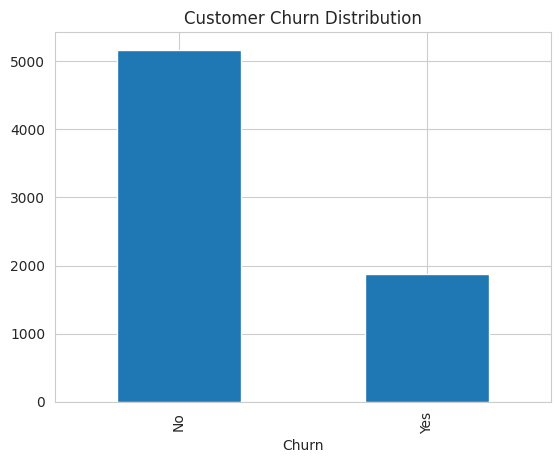

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges:', df['TotalCharges'].isna().sum())
print(df['Churn'].value_counts())

df['Churn'].value_counts().plot(kind='bar')
plt.title('Customer Churn Distribution')
plt.show()

## 3. Split data and preprocess features
We split before SMOTE so the test data stays untouched. OneHotEncoder converts text categories into numbers.

In [4]:
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

num_steps = Pipeline([
    ('fill', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
cat_steps = Pipeline([
    ('fill', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocess = ColumnTransformer([
    ('num', num_steps, num_cols),
    ('cat', cat_steps, cat_cols)
])
print('Numerical columns:', num_cols)
print('Categorical columns:', cat_cols)

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 4. Train Random Forest and XGBoost
SMOTE is inside each pipeline, so it only oversamples training folds during cross-validation. We use ROC-AUC to compare the models.

In [5]:
rf = ImbPipeline([
    ('prepare', preprocess),
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                     random_state=42, n_jobs=-1))
])

xgb = ImbPipeline([
    ('prepare', preprocess),
    ('smote', SMOTE(random_state=42)),
    ('model', XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05,
                            subsample=0.9, colsample_bytree=0.9,
                            eval_metric='logloss', random_state=42, n_jobs=2))
])

models = {'Random Forest': rf, 'XGBoost': xgb}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probabilities)
    results.append({'Model': name, 'CV ROC-AUC': scores.mean(), 'Test ROC-AUC': auc})
    print(name, '- CV ROC-AUC:', round(scores.mean(), 4),
          '- Test ROC-AUC:', round(auc, 4))

results_df = pd.DataFrame(results)
display(results_df)

Random Forest - CV ROC-AUC: 0.8355 - Test ROC-AUC: 0.8322


XGBoost - CV ROC-AUC: 0.8459 - Test ROC-AUC: 0.8419


,Model,CV ROC-AUC,Test ROC-AUC
0,Random Forest,0.835462,0.832225
1,XGBoost,0.845889,0.841889


## 5. Plot ROC curves

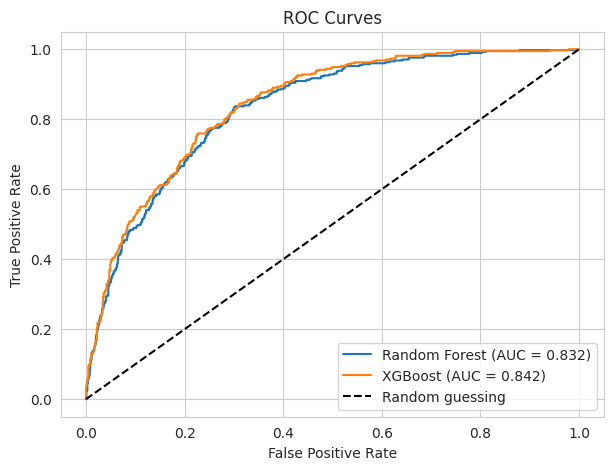

In [6]:
plt.figure(figsize=(7, 5))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()

## 6. Confusion matrices and classification reports


 Random Forest
              precision    recall  f1-score   support

    No Churn       0.86      0.83      0.84      1035
       Churn       0.57      0.63      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.78      0.78      1409


 XGBoost
              precision    recall  f1-score   support

    No Churn       0.87      0.81      0.84      1035
       Churn       0.56      0.66      0.61       374

    accuracy                           0.77      1409
   macro avg       0.72      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409



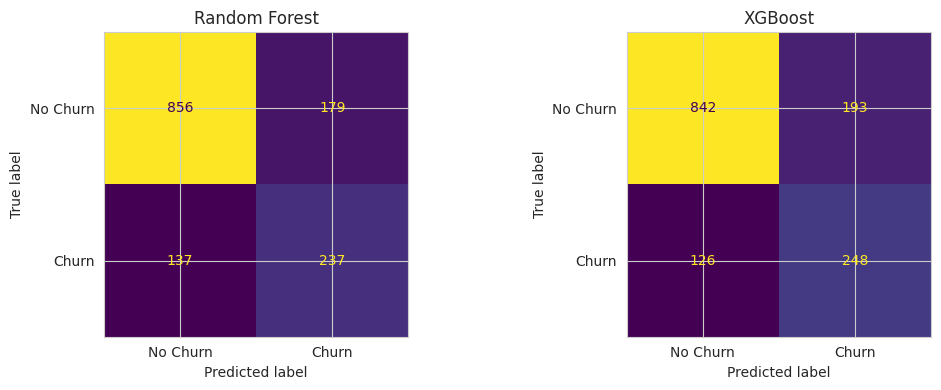

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    predictions = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, predictions,
                                            display_labels=['No Churn', 'Churn'], ax=ax,
                                            colorbar=False)
    ax.set_title(name)
    print('\n', name)
    print(classification_report(y_test, predictions, target_names=['No Churn', 'Churn']))
plt.tight_layout()
plt.show()

## 7. Top 10 important features
Feature importance shows which variables the models used most. It does not prove causation.

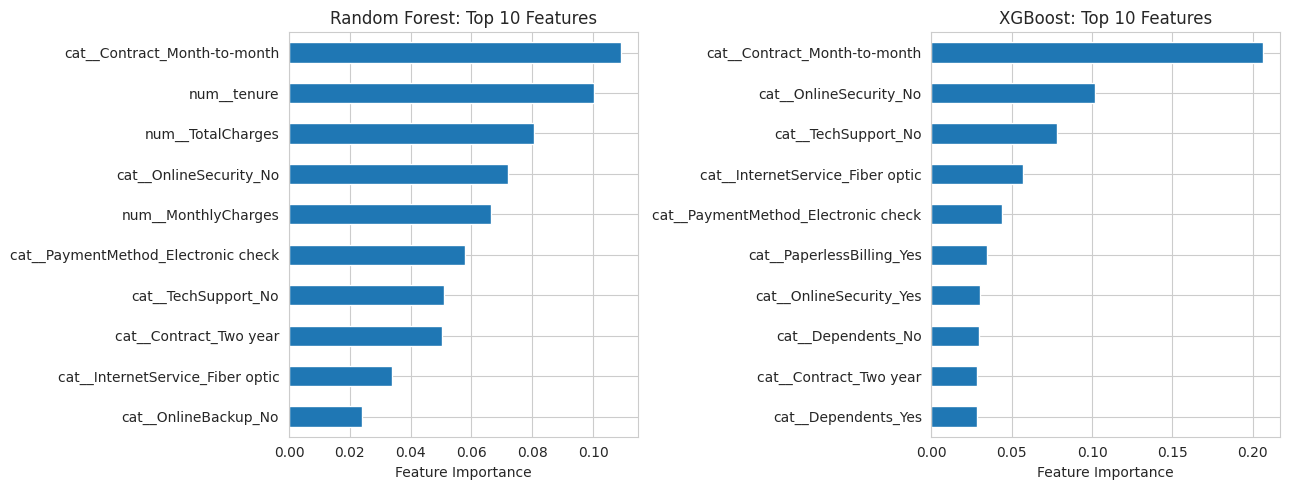

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, models.items()):
    feature_names = model.named_steps['prepare'].get_feature_names_out()
    importance = model.named_steps['model'].feature_importances_
    top = pd.Series(importance, index=feature_names).nlargest(10).sort_values()
    top.plot(kind='barh', ax=ax)
    ax.set_title(name + ': Top 10 Features')
    ax.set_xlabel('Feature Importance')
plt.tight_layout()
plt.show()

## 8. Final conclusion

In [9]:
best = results_df.loc[results_df['Test ROC-AUC'].idxmax()]
print('Best model on the test set:', best['Model'])
print('ROC-AUC:', round(best['Test ROC-AUC'], 4))
if best['Test ROC-AUC'] >= 0.80:
    print('The target ROC-AUC of 80% was achieved.')
else:
    print('The target ROC-AUC of 80% was not achieved.')
print('Note: Compare CV scores when selecting a model; test scores are for final evaluation.')

Best model on the test set: XGBoost
ROC-AUC: 0.8419
The target ROC-AUC of 80% was achieved.
Note: Compare CV scores when selecting a model; test scores are for final evaluation.
